<a href="https://colab.research.google.com/github/SEU-USUARIO/SEU-REPOSITORIO/blob/main/Unidade2_Analise_e_Ciencia_de_Dados/Ciencia_Dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

02/09  
**II – Análise e Ciência de Dados**

* Visualização e interpretação de dados
* Aula prática + resolução colaborativa de problemas
* Criar gráficos e interpretar informações obtidas dos dados
* Dashboard ou conjunto de visualizações comentadas

**Nome:** Gustavo Carvalho de Oliveira | UDF – Centro Universitário | Sistemas de Informação  
**Professora:** Kadidja Valéria

**Tema:** pedidos de uma loja on-line de informática no Distrito Federal (agosto de 2026). **Dados fictícios**, criados para a atividade.

**Pergunta norteadora:** onde estão os atrasos de entrega e o que eles têm a ver com a satisfação do cliente?

**Referência:** CARVALHO, André Carlos de; MENEZES, Angelo; BONIDIA, Robson. *Ciência de Dados — Fundamentos e Aplicações*. Capítulo “Python para Ciência de Dados”. Disponível em: https://bonidia.github.io/cd-fundamentos/cp2.html. Acesso em: 2 set. 2026.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Series e DataFrame

In [2]:
status_possiveis = pd.Series(['Entregue', 'Em transporte', 'Cancelado'], name='status')
exemplo = pd.DataFrame({'id_pedido': ['PD001', 'PD002'], 'prazo_entrega_dias': [2, 5]})
print(status_possiveis)
exemplo

0         Entregue
1    Em transporte
2        Cancelado
Name: status, dtype: str


,id_pedido,prazo_entrega_dias
0,PD001,2
1,PD002,5


## 2. Base de dados
A célula abaixo grava o arquivo `pedidos_loja_online.csv` (assim o notebook funciona no Colab sem upload) e em seguida o lê com `read_csv`.

In [3]:
dados_csv = """id_pedido,data_pedido,regiao,categoria,pagamento,status,prazo_entrega_dias,avaliacao
PD001,2026-08-01,Asa Norte,Periférico,Pix,Entregue,1,5
PD002,2026-08-01,Taguatinga,Notebook,Cartão,Entregue,3,4
PD003,2026-08-02,Ceilândia,Celular,Boleto,Entregue,7,2
PD004,2026-08-03,Águas Claras,Acessório,Pix,Entregue,2,5
PD005,2026-08-04,Asa Sul,Monitor,Cartão,Entregue,2,4
PD006,2026-08-05,Ceilândia,Periférico,Pix,Entregue,5,3
PD007,2026-08-06,Asa Norte,Notebook,Boleto,Cancelado,,
PD008,2026-08-07,Taguatinga,Acessório,Pix,Entregue,2,5
PD009,2026-08-08,Asa Sul,Celular,Cartão,Entregue,1,5
PD010,2026-08-09,Ceilândia,Monitor,Boleto,Entregue,15,1
PD011,2026-08-10,Águas Claras,Notebook,Cartão,Entregue,3,4
PD012,2026-08-11,Asa Norte,Acessório,Pix,Entregue,1,4
PD013,2026-08-12,Taguatinga,Periférico,Boleto,Entregue,6,3
PD014,2026-08-14,Ceilândia,Acessório,Cartão,Entregue,6,2
PD015,2026-08-16,Asa Sul,Notebook,Pix,Entregue,2,5
PD016,2026-08-18,Águas Claras,Celular,Boleto,Cancelado,,
PD017,2026-08-20,Taguatinga,Monitor,Cartão,Entregue,4,4
PD018,2026-08-22,Asa Norte,Periférico,Cartão,Entregue,2,5
PD019,2026-08-27,Ceilândia,Celular,Pix,Em transporte,,
PD020,2026-08-29,Asa Sul,Acessório,Boleto,Em transporte,,
"""
with open('pedidos_loja_online.csv', 'w', encoding='utf-8') as f:
    f.write(dados_csv)

df = pd.read_csv('pedidos_loja_online.csv')
df.head()

,id_pedido,data_pedido,regiao,categoria,pagamento,status,prazo_entrega_dias,avaliacao
0,PD001,2026-08-01,Asa Norte,Periférico,Pix,Entregue,1.0,5.0
1,PD002,2026-08-01,Taguatinga,Notebook,Cartão,Entregue,3.0,4.0
2,PD003,2026-08-02,Ceilândia,Celular,Boleto,Entregue,7.0,2.0
3,PD004,2026-08-03,Águas Claras,Acessório,Pix,Entregue,2.0,5.0
4,PD005,2026-08-04,Asa Sul,Monitor,Cartão,Entregue,2.0,4.0


In [4]:
df.tail(3)

,id_pedido,data_pedido,regiao,categoria,pagamento,status,prazo_entrega_dias,avaliacao
17,PD018,2026-08-22,Asa Norte,Periférico,Cartão,Entregue,2.0,5.0
18,PD019,2026-08-27,Ceilândia,Celular,Pix,Em transporte,NaN,NaN
19,PD020,2026-08-29,Asa Sul,Acessório,Boleto,Em transporte,NaN,NaN


In [5]:
df.shape

(20, 8)

In [6]:
df.columns

Index(['id_pedido', 'data_pedido', 'regiao', 'categoria', 'pagamento',
       'status', 'prazo_entrega_dias', 'avaliacao'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           20 non-null     str    
 1   data_pedido         20 non-null     str    
 2   regiao              20 non-null     str    
 3   categoria           20 non-null     str    
 4   pagamento           20 non-null     str    
 5   status              20 non-null     str    
 6   prazo_entrega_dias  16 non-null     float64
 7   avaliacao           16 non-null     float64
dtypes: float64(2), str(6)
memory usage: 1.4 KB


In [8]:
df.describe()

,prazo_entrega_dias,avaliacao
count,16.00000,16.000000
mean,3.87500,3.812500
std,3.53789,1.276388
min,1.00000,1.000000
25%,2.00000,3.000000
50%,2.50000,4.000000
75%,5.25000,5.000000
max,15.00000,5.000000


**Leitura:** são 20 pedidos e 8 colunas. `prazo_entrega_dias` e `avaliacao` têm só 16 valores: os 4 que faltam são pedidos cancelados ou ainda em transporte, ou seja, a ausência é esperada e não um erro de cadastro. A média do prazo (~3,9 dias) é maior que a mediana (2,5 dias) por causa de um pedido de 15 dias.

## 3. Seleção de colunas e linhas

In [9]:
df['regiao']

0        Asa Norte
1       Taguatinga
2        Ceilândia
3     Águas Claras
4          Asa Sul
5        Ceilândia
6        Asa Norte
7       Taguatinga
8          Asa Sul
9        Ceilândia
10    Águas Claras
11       Asa Norte
12      Taguatinga
13       Ceilândia
14         Asa Sul
15    Águas Claras
16      Taguatinga
17       Asa Norte
18       Ceilândia
19         Asa Sul
Name: regiao, dtype: str

In [10]:
df[['id_pedido', 'regiao', 'status']]

,id_pedido,regiao,status
0,PD001,Asa Norte,Entregue
1,PD002,Taguatinga,Entregue
2,PD003,Ceilândia,Entregue
3,PD004,Águas Claras,Entregue
4,PD005,Asa Sul,Entregue
5,PD006,Ceilândia,Entregue
6,PD007,Asa Norte,Cancelado
7,PD008,Taguatinga,Entregue
8,PD009,Asa Sul,Entregue
9,PD010,Ceilândia,Entregue


In [11]:
df.loc[0:2, ['id_pedido', 'regiao']]  # loc usa rótulos: inclui a linha 2

,id_pedido,regiao
0,PD001,Asa Norte
1,PD002,Taguatinga
2,PD003,Ceilândia


In [12]:
df.iloc[0:3, 0:2]  # iloc usa posições: não inclui a posição 3

,id_pedido,data_pedido
0,PD001,2026-08-01
1,PD002,2026-08-01
2,PD003,2026-08-02


## 4. Filtros

In [13]:
df[df['pagamento'] == 'Boleto']

,id_pedido,data_pedido,regiao,categoria,pagamento,status,prazo_entrega_dias,avaliacao
2,PD003,2026-08-02,Ceilândia,Celular,Boleto,Entregue,7.0,2.0
6,PD007,2026-08-06,Asa Norte,Notebook,Boleto,Cancelado,NaN,NaN
9,PD010,2026-08-09,Ceilândia,Monitor,Boleto,Entregue,15.0,1.0
12,PD013,2026-08-12,Taguatinga,Periférico,Boleto,Entregue,6.0,3.0
15,PD016,2026-08-18,Águas Claras,Celular,Boleto,Cancelado,NaN,NaN
19,PD020,2026-08-29,Asa Sul,Acessório,Boleto,Em transporte,NaN,NaN


In [14]:
df[(df['status'] == 'Entregue') & (df['prazo_entrega_dias'] > 4)]  # entregas atrasadas (mais de 4 dias)

,id_pedido,data_pedido,regiao,categoria,pagamento,status,prazo_entrega_dias,avaliacao
2,PD003,2026-08-02,Ceilândia,Celular,Boleto,Entregue,7.0,2.0
5,PD006,2026-08-05,Ceilândia,Periférico,Pix,Entregue,5.0,3.0
9,PD010,2026-08-09,Ceilândia,Monitor,Boleto,Entregue,15.0,1.0
12,PD013,2026-08-12,Taguatinga,Periférico,Boleto,Entregue,6.0,3.0
13,PD014,2026-08-14,Ceilândia,Acessório,Cartão,Entregue,6.0,2.0


In [15]:
df[df['regiao'].isin(['Ceilândia', 'Taguatinga'])]

,id_pedido,data_pedido,regiao,categoria,pagamento,status,prazo_entrega_dias,avaliacao
1,PD002,2026-08-01,Taguatinga,Notebook,Cartão,Entregue,3.0,4.0
2,PD003,2026-08-02,Ceilândia,Celular,Boleto,Entregue,7.0,2.0
5,PD006,2026-08-05,Ceilândia,Periférico,Pix,Entregue,5.0,3.0
7,PD008,2026-08-07,Taguatinga,Acessório,Pix,Entregue,2.0,5.0
9,PD010,2026-08-09,Ceilândia,Monitor,Boleto,Entregue,15.0,1.0
12,PD013,2026-08-12,Taguatinga,Periférico,Boleto,Entregue,6.0,3.0
13,PD014,2026-08-14,Ceilândia,Acessório,Cartão,Entregue,6.0,2.0
16,PD017,2026-08-20,Taguatinga,Monitor,Cartão,Entregue,4.0,4.0
18,PD019,2026-08-27,Ceilândia,Celular,Pix,Em transporte,NaN,NaN


## 5. Conversão de tipos e nova coluna

In [16]:
df['data_pedido'] = pd.to_datetime(df['data_pedido'])
df['avaliacao'] = df['avaliacao'].astype('Int64')   # inteiro que aceita valor ausente
df['prazo_semanas'] = df['prazo_entrega_dias'] / 7
df['dia_semana'] = df['data_pedido'].dt.day_name()
df['atrasado'] = df['prazo_entrega_dias'] > 4
df.dtypes

id_pedido                        str
data_pedido           datetime64[us]
regiao                           str
categoria                        str
pagamento                        str
status                           str
prazo_entrega_dias           float64
avaliacao                      Int64
prazo_semanas                float64
dia_semana                       str
atrasado                        bool
dtype: object

## 6. Agregações

In [17]:
df['status'].value_counts()

status
Entregue         16
Cancelado         2
Em transporte     2
Name: count, dtype: int64

In [18]:
df['prazo_entrega_dias'].mean()

np.float64(3.875)

In [19]:
df.groupby('regiao')['prazo_entrega_dias'].mean().sort_values(ascending=False)

regiao
Ceilândia       8.250000
Taguatinga      3.750000
Águas Claras    2.500000
Asa Sul         1.666667
Asa Norte       1.333333
Name: prazo_entrega_dias, dtype: float64

In [20]:
df.groupby('pagamento')[['prazo_entrega_dias', 'avaliacao']].mean().round(2)

,prazo_entrega_dias,avaliacao
pagamento,,
Boleto,9.33,2.0
Cartão,3.00,4.0
Pix,2.17,4.5


## 7. Visualizações comentadas

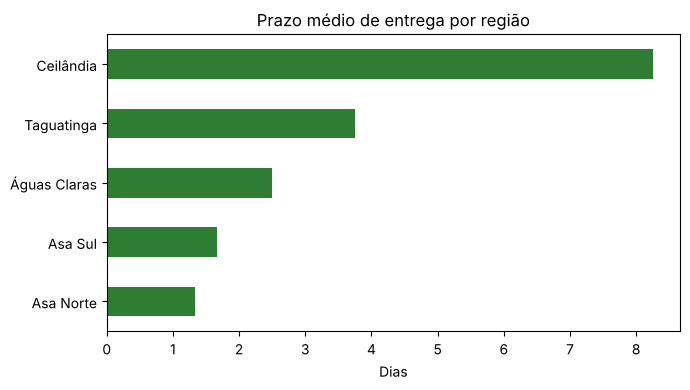

In [21]:
prazo_regiao = df.groupby('regiao')['prazo_entrega_dias'].mean().sort_values()
ax = prazo_regiao.plot(kind='barh', color='#2e7d32', figsize=(7, 4))
ax.set_title('Prazo médio de entrega por região')
ax.set_xlabel('Dias'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Gráfico 1:** Ceilândia tem o maior prazo médio (8,25 dias), mais que o dobro de Taguatinga (3,75) e cerca de seis vezes o da Asa Norte (1,33). Essa média é puxada pelo pedido PD010 (15 dias), mas, mesmo sem ele, Ceilândia continuaria bem acima das demais (6 dias).

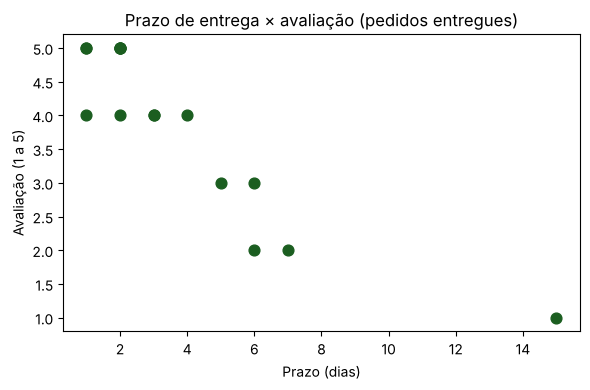

Correlação prazo × avaliação: -0.89


In [22]:
entregues = df[df['status'] == 'Entregue']
ax = entregues.plot(kind='scatter', x='prazo_entrega_dias', y='avaliacao', s=60, color='#1b5e20', figsize=(6, 4))
ax.set_title('Prazo de entrega × avaliação (pedidos entregues)')
ax.set_xlabel('Prazo (dias)'); ax.set_ylabel('Avaliação (1 a 5)')
plt.tight_layout(); plt.show()
print('Correlação prazo × avaliação:', round(entregues['prazo_entrega_dias'].corr(entregues['avaliacao'].astype(float)), 2))

**Gráfico 2:** quanto maior o prazo, menor a nota: a correlação é −0,89, fortemente negativa. Todas as notas 1 e 2 aparecem em entregas de 6 dias ou mais. Isso é uma associação em 16 pedidos fictícios; não prova que o atraso **causa** a nota baixa (o produto ou o atendimento também podem influenciar).

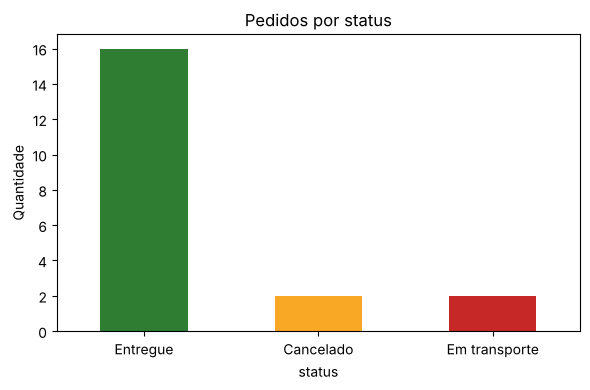

In [23]:
contagem = df['status'].value_counts()
ax = contagem.plot(kind='bar', color=['#2e7d32', '#f9a825', '#c62828'], figsize=(6, 4), rot=0)
ax.set_title('Pedidos por status'); ax.set_ylabel('Quantidade')
plt.tight_layout(); plt.show()

**Gráfico 3:** 16 dos 20 pedidos (80%) foram entregues; 2 cancelados e 2 em transporte. Os dois em transporte são do fim do mês, então ainda é cedo para chamar de atraso.

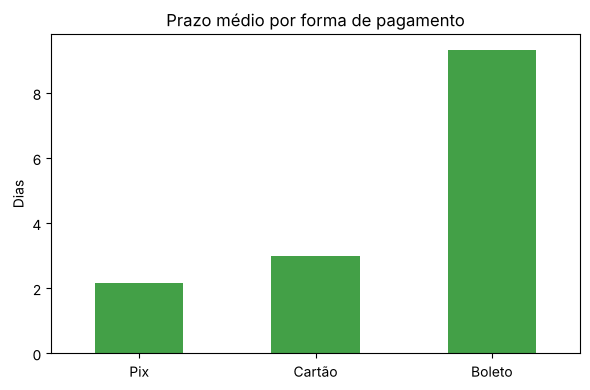

In [24]:
ax = df.groupby('pagamento')['prazo_entrega_dias'].mean().sort_values().plot(kind='bar', color='#43a047', rot=0, figsize=(6, 4))
ax.set_title('Prazo médio por forma de pagamento'); ax.set_ylabel('Dias'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Gráfico 4:** pedidos pagos com boleto levaram em média 9,33 dias e tiveram nota média 2,0, contra 2,17 dias e nota 4,5 no Pix. Uma explicação possível é o tempo de compensação do boleto antes do envio. Há porém um fator misturado: 2 dos 3 boletos entregues são de Ceilândia, a região mais lenta. Separar os dois efeitos exigiria mais pedidos e a data de pagamento, que não está na base.

## 8. Conclusões

1. **Ceilândia** concentra os maiores prazos, e o atraso aparece mesmo sem o caso extremo. Vale investigar a transportadora e a rota dessa região.
2. **Prazo e satisfação andam juntos:** entregas acima de 4 dias tiveram as piores avaliações.
3. **Boleto** aparece com prazos maiores, mas esse efeito está misturado com o da região (a maioria dos boletos entregues é de Ceilândia).
4. **Limites:** só 20 pedidos fictícios de um mês; as médias por região usam de 2 a 4 pedidos entregues cada e mudam muito com um único caso. As conclusões são hipóteses para investigar com mais dados, não fatos sobre a loja.